In [1]:
import json
import glob
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

In [2]:
H_CM = 270
FOV_X = 159.5
FOV_Y = 119.8

In [3]:
def undistort(img, K, D, DIM):
    h,w = img.shape[:2]
    map1, map2 = cv2.fisheye.initUndistortRectifyMap(K, D, np.eye(3), K, DIM, cv2.CV_16SC2)
    undistorted_img = cv2.remap(img, map1, map2, interpolation=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
    return undistorted_img

def undistort_upd(img, K, D, DIM, balance=0.0, dim2=None, dim3=None):
    dim1 = img.shape[:2][::-1]  #dim1 is the dimension of input image to un-distort
    assert dim1[0]/dim1[1] == DIM[0]/DIM[1], "Image to undistort needs to have same aspect ratio as the ones used in calibration"
    if not dim2:
        dim2 = dim1
    if not dim3:
        dim3 = dim1
    scaled_K = K * dim1[0] / DIM[0]  # The values of K is to scale with image dimension.
    scaled_K[2][2] = 1.0  # Except that K[2][2] is always 1.0
    # This is how scaled_K, dim2 and balance are used to determine the final K used to un-distort image. OpenCV document failed to make this clear!
    new_K = cv2.fisheye.estimateNewCameraMatrixForUndistortRectify(scaled_K, D, dim2, np.eye(3), balance=balance)
    map1, map2 = cv2.fisheye.initUndistortRectifyMap(scaled_K, D, np.eye(3), new_K, dim3, cv2.CV_16SC2)
    undistorted_img = cv2.remap(img, map1, map2, interpolation=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
    return undistorted_img

In [4]:
def calibrate(imgs):
    CHECKERBOARD = (6,9)
    subpix_criteria = (cv2.TERM_CRITERIA_EPS+cv2.TERM_CRITERIA_MAX_ITER, 30, 0.1)
    calibration_flags = cv2.fisheye.CALIB_RECOMPUTE_EXTRINSIC+cv2.fisheye.CALIB_CHECK_COND+cv2.fisheye.CALIB_FIX_SKEW
    objp = np.zeros((1, CHECKERBOARD[0]*CHECKERBOARD[1], 3), np.float32)
    objp[0,:,:2] = np.mgrid[0:CHECKERBOARD[0], 0:CHECKERBOARD[1]].T.reshape(-1, 2)

    _img_shape = None

    objpoints = [] # 3d point in real world space
    imgpoints = [] # 2d points in image plane.

    for img in imgs:
        _img_shape = img.shape[:2]
        # Find the chess board corners
        ret, corners = cv2.findChessboardCorners(img, CHECKERBOARD, cv2.CALIB_CB_ADAPTIVE_THRESH+cv2.CALIB_CB_FAST_CHECK+cv2.CALIB_CB_NORMALIZE_IMAGE)
        # ret, corners = cv2.findChessboardCorners(img, CHECKERBOARD, None)
        # If found, add object points, image points (after refining them)
        if ret == True:
            objpoints.append(objp)
            cv2.cornerSubPix(img,corners,(3,3),(-1,-1),subpix_criteria)
            imgpoints.append(corners)

    N_OK = len(objpoints)
    K = np.zeros((3, 3))
    D = np.zeros((4, 1))
    rvecs = [np.zeros((1, 1, 3), dtype=np.float64) for i in range(N_OK)]
    tvecs = [np.zeros((1, 1, 3), dtype=np.float64) for i in range(N_OK)]
    rms, _, _, _, _ = \
        cv2.fisheye.calibrate(
            objpoints,
            imgpoints,
            img.shape[::-1],
            K,
            D,
            rvecs,
            tvecs,
            calibration_flags,
            (cv2.TERM_CRITERIA_EPS+cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-6)
        )
    print("Found " + str(N_OK) + " valid images for calibration")
    print("DIM=" + str(_img_shape[::-1]))
    print("K=np.array(" + str(K.tolist()) + ")")
    print("D=np.array(" + str(D.tolist()) + ")")

    return K, D, _img_shape[::-1]


In [6]:
vpaths = sorted(glob.glob("videos/*.avi"))

for vpath in vpaths:
    vname = os.path.basename(vpath)
    print(vname)
    
    imgs = []
    cap = cv2.VideoCapture(vpath)
    i = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        i += 1
        imgs.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))
    print(len(imgs))
    try:
        K, D, DIM = calibrate(imgs)
        
    except Exception as e:
        print("error in calibration")
    
    with open(os.path.join("params", vname[:-4] + ".json"), "w") as f:
        json.dump({
            "IMG_W": DIM[0],
            "IMG_H": DIM[1],
            "LENS_PARAMS": {
                "CX": K[0, 2],
                "CY": K[1, 2],
                "FX": K[0, 0],
                "FY": K[1, 1],
                "K0": D[0, 0],
                "K1": D[1, 0],
                "K2": D[2, 0],
                "K3": D[3, 0],
                "FOV_X": FOV_X,
                "FOV_Y": FOV_Y,
            }}, f, indent=4)


pg2-video_20241119142311.avi
53
Found 35 valid images for calibration
DIM=(640, 480)
K=np.array([[224.14954932140768, 0.0, 311.3663758768294], [0.0, 224.75000489323241, 243.07259484477763], [0.0, 0.0, 1.0]])
D=np.array([[-0.0007271131462745428], [0.028021937666020968], [-0.028018518097412643], [0.010495350157317156]])
pg2-video_20241119142445.avi
105
Found 79 valid images for calibration
DIM=(640, 480)
K=np.array([[227.70268017183332, 0.0, 312.88050230153624], [0.0, 228.61990004665438, 241.5989918554312], [0.0, 0.0, 1.0]])
D=np.array([[-0.003670775210713351], [0.018499178874657574], [-0.015365654566357027], [0.004371459326472153]])


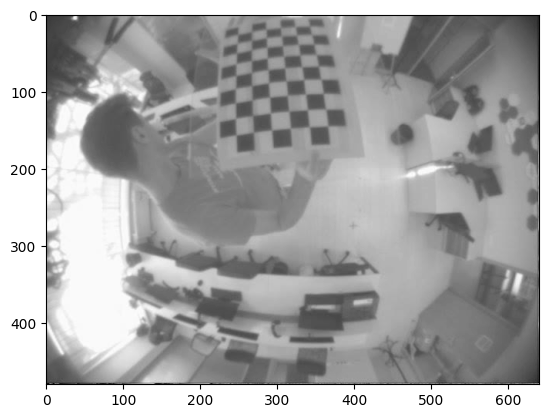

In [7]:
img = imgs[10].copy()
plt.imshow(img, cmap='gray')

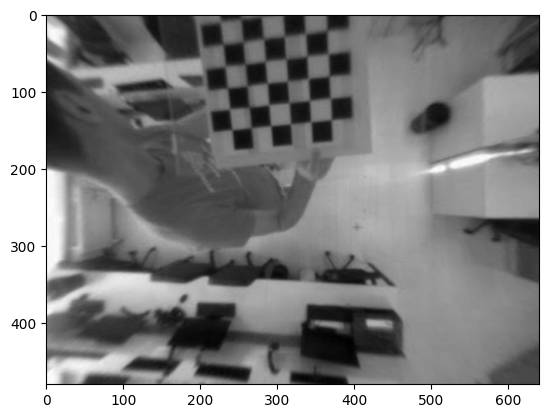

In [8]:
plt.imshow(undistort(img, K, D, DIM), cmap='gray')

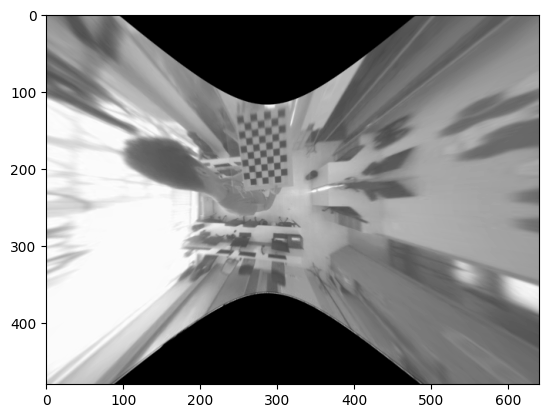

In [9]:
plt.imshow(undistort_upd(img, K, D, DIM, 0.8), cmap='gray')